# Cookie Cats A/B 미니분석

## 1. 가설과 지표 (데이터 보기 전 작성)

- 가설: 장벽을 30레벨에서 40레벨로 미루면 7일 리텐션이 달라진다
  - 귀무가설: 차이 없음 / 양측 검정 / 유의수준 0.05
- 주지표: `retention_7` / 보조지표: `retention_1` / 가드레일: `sum_gamerounds`
- 주지표를 고른 이유: 1일 리텐션은 게임에 대한 첫인상이라 게이트에 닿기 전 이탈이 많이 섞여 있을 수 있고, 게이트를 겪은 뒤에도 돌아오는지는 7일 리텐션에서 볼 수 있다고 판단해 주지표로 설정함.

## 2. 데이터 확인

확인할 것:
1. 행 수, `userid` 중복, 결측
2. `sum_gamerounds` 분포와 최댓값. 극단값은 지우지 않고 표시만 하고, 포함·제외 결과를 나란히 본다
3. 그룹별 0라운드 유저 비율

집계는 DuckDB SQL로 한다.

### 2-0. 데이터 불러오기

CSV를 DuckDB 테이블 `cc`로 읽고 앞 5행과 컬럼 타입을 본다.

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute("CREATE TABLE cc AS SELECT * FROM read_csv_auto('data/cookie_cats.csv')")
con.sql("SELECT * FROM cc LIMIT 5").df()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
con.sql("DESCRIBE cc").df()[['column_name', 'column_type']]

,column_name,column_type
0,userid,BIGINT
1,version,VARCHAR
2,sum_gamerounds,BIGINT
3,retention_1,BOOLEAN
4,retention_7,BOOLEAN


### 2-1. 행 수, `userid` 중복, 결측

`n_rows`와 `n_unique_userid`가 같으면 한 행이 한 유저다. 결측은 컬럼별로 센다.

In [3]:
con.sql("""
SELECT
    COUNT(*)                              AS n_rows,
    COUNT(DISTINCT userid)                AS n_unique_userid,
    COUNT(*) - COUNT(DISTINCT userid)     AS n_dup_userid,
    COUNT(*) - COUNT(userid)              AS null_userid,
    COUNT(*) - COUNT(version)             AS null_version,
    COUNT(*) - COUNT(sum_gamerounds)      AS null_sum_gamerounds,
    COUNT(*) - COUNT(retention_1)         AS null_retention_1,
    COUNT(*) - COUNT(retention_7)         AS null_retention_7
FROM cc
""").df().T.rename(columns={0: 'value'})

,value
n_rows,90189
n_unique_userid,90189
n_dup_userid,0
null_userid,0
null_version,0
null_sum_gamerounds,0
null_retention_1,0
null_retention_7,0


### 2-2. `sum_gamerounds` 분포와 최댓값

전체 분위수와 최댓값을 보고, 값이 큰 순서로 상위 10명을 확인한다.

In [4]:
con.sql("""
SELECT
    MIN(sum_gamerounds)                                         AS min,
    QUANTILE_CONT(sum_gamerounds, 0.25)                         AS p25,
    MEDIAN(sum_gamerounds)                                      AS median,
    QUANTILE_CONT(sum_gamerounds, 0.75)                         AS p75,
    QUANTILE_CONT(sum_gamerounds, 0.99)                         AS p99,
    QUANTILE_CONT(sum_gamerounds, 0.999)                        AS p999,
    MAX(sum_gamerounds)                                         AS max,
    ROUND(AVG(sum_gamerounds), 2)                               AS mean
FROM cc
""").df()

,min,p25,median,p75,p99,p999,max,mean
0,0,5.0,16.0,51.0,493.0,1073.624,49854,51.87


In [5]:
con.sql("""
SELECT userid, version, sum_gamerounds, retention_1, retention_7
FROM cc
ORDER BY sum_gamerounds DESC
LIMIT 10
""").df()

,userid,version,sum_gamerounds,retention_1,retention_7
0,6390605,gate_30,49854,False,True
1,871500,gate_30,2961,True,True
2,3271615,gate_40,2640,True,False
3,4832608,gate_30,2438,True,True
4,5346171,gate_40,2294,True,True
5,5133952,gate_30,2251,True,True
6,9640085,gate_30,2156,True,True
7,4090246,gate_40,2124,True,True
8,9791599,gate_40,2063,True,True
9,725080,gate_40,2015,True,True


### 2-3. 극단값 표시

최댓값 49,854는 2위(2,961)의 약 17배로 나머지와 동떨어져 있다. 행은 지우지 않고 `is_extreme` 플래그만 붙인다.

- **확정 기준**: userid 6390605 한 명만 극단값으로 표시
- 이후 처리 방침
  - 라운드 수 통계(`sum_gamerounds`): 이 유저를 **제외**하고 계산
  - 리텐션 집계·검정: 이 유저를 **포함한 결과와 제외한 결과를 둘 다** 제시

In [6]:
EXTREME_USERID = 6390605

con.execute(f"""
CREATE OR REPLACE TABLE cc_flag AS
SELECT *,
       userid = {EXTREME_USERID} AS is_extreme
FROM cc
""")
con.sql("SELECT * FROM cc_flag WHERE is_extreme").df()

,userid,version,sum_gamerounds,retention_1,retention_7,is_extreme
0,6390605,gate_30,49854,False,True,True


### 2-4. 극단값 포함·제외 비교 (그룹별)

극단값 1명이 평균과 표준편차를 얼마나 바꾸는지 그룹별로 비교한다. 중앙값은 거의 그대로일 것으로 예상한다.

In [7]:
con.sql("""
WITH base AS (
    SELECT 'all'               AS sample, * FROM cc_flag
    UNION ALL
    SELECT 'excl_extreme'      AS sample, * FROM cc_flag WHERE NOT is_extreme
)
SELECT
    sample,
    version,
    COUNT(*)                              AS n_users,
    ROUND(AVG(sum_gamerounds), 2)         AS mean,
    ROUND(STDDEV_SAMP(sum_gamerounds), 2) AS std,
    MEDIAN(sum_gamerounds)                AS median,
    MAX(sum_gamerounds)                   AS max
FROM base
GROUP BY sample, version
ORDER BY sample, version
""").df()

,sample,version,n_users,mean,std,median,max
0,all,gate_30,44700,52.46,256.72,17.0,49854
1,all,gate_40,45489,51.30,103.29,16.0,2640
2,excl_extreme,gate_30,44699,51.34,102.06,17.0,2961
3,excl_extreme,gate_40,45489,51.30,103.29,16.0,2640


분포 그림: 왼쪽은 극단값 포함 상자그림, 오른쪽은 극단값 제외 상자그림이다.

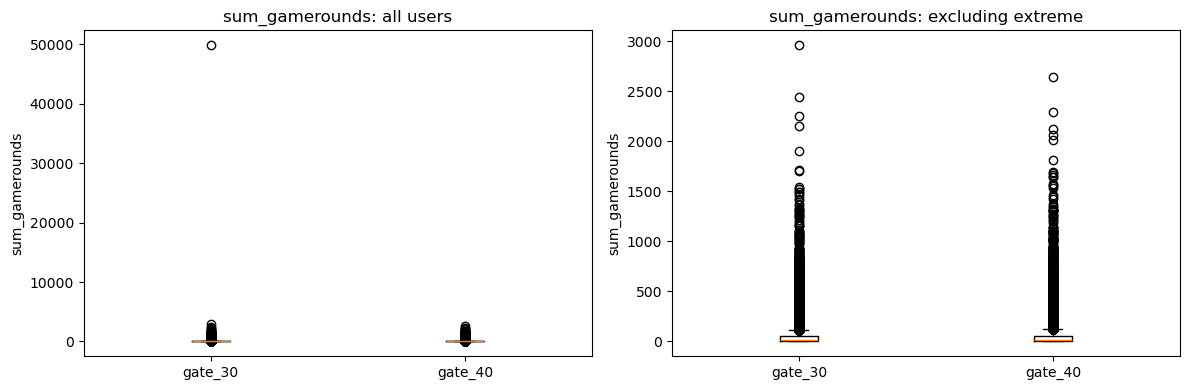

In [8]:
df_flag = con.sql("SELECT version, sum_gamerounds, is_extreme FROM cc_flag").df()
groups = ['gate_30', 'gate_40']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, d) in zip(axes, [('all users', df_flag),
                                 ('excluding extreme', df_flag[~df_flag['is_extreme']])]):
    ax.boxplot([d.loc[d['version'] == g, 'sum_gamerounds'] for g in groups])
    ax.set_xticks([1, 2], groups)
    ax.set_title(f'sum_gamerounds: {title}')
    ax.set_ylabel('sum_gamerounds')
plt.tight_layout()
plt.show()

### 2-5. 그룹별 0라운드 유저 비율

설치 후 한 판도 안 한 유저 비율이 두 그룹에서 비슷한지 본다.

In [9]:
con.sql("""
SELECT
    version,
    COUNT(*)                                          AS n_users,
    COUNT(*) FILTER (WHERE sum_gamerounds = 0)        AS n_zero_round,
    ROUND(AVG((sum_gamerounds = 0)::INT) * 100, 2)    AS zero_round_pct
FROM cc
GROUP BY version
ORDER BY version
""").df()

,version,n_users,n_zero_round,zero_round_pct
0,gate_30,44700,1937,4.33
1,gate_40,45489,2057,4.52


### 2단계 정리

- 90,189행, `userid` 중복 0, 모든 컬럼 결측 0 → 한 행 = 한 유저
- `sum_gamerounds`는 오른쪽 꼬리가 긴 분포 (중앙값 16, p99 493, 최댓값 49,854)
- 극단값: gate_30의 userid 6390605 (49,854라운드, 2위 2,961의 약 17배). 지우지 않고 `is_extreme`으로 표시
  - 빼면 gate_30 평균 52.46 → 51.34, 표준편차 256.72 → 102.06, 중앙값은 17로 그대로
  - 이 유저는 `retention_1` = False, `retention_7` = True
- 0라운드 유저 비율: gate_30 4.33%, gate_40 4.52%로 비슷
- 처리 방침(확정): 라운드 수 통계는 이 유저 제외, 리텐션은 포함·제외 결과를 둘 다 제시

## 3. 실험 품질 점검 (SRM)

두 그룹이 설계대로 50:50으로 배정되었는지 카이제곱 적합도 검정으로 확인한다.

- 배정 자체를 점검하는 단계라서 극단값 유저를 포함한 전체 유저로 본다 (1명이라 결과에 영향 없음)
- 판단 기준(가이드): p값이 매우 작으면(0.001 미만) 배정 오류를 의심하고 한계로 적는다

In [10]:
srm = con.sql("""
SELECT version, COUNT(*) AS n_users
FROM cc
GROUP BY version
ORDER BY version
""").df()
srm['ratio'] = (srm['n_users'] / srm['n_users'].sum()).round(4)
srm

,version,n_users,ratio
0,gate_30,44700,0.4956
1,gate_40,45489,0.5044


In [11]:
from scipy.stats import chisquare

observed = srm['n_users'].to_numpy()
expected = [observed.sum() / 2] * 2
chi2, p_srm = chisquare(observed, f_exp=expected)
print(f'관측: {dict(zip(srm.version, observed.tolist()))}')
print(f'기대: {expected[0]:.1f} / {expected[1]:.1f}')
print(f'chi2 = {chi2:.3f}, p = {p_srm:.4f}')
print('배정 오류 의심 (p < 0.001):', p_srm < 0.001)

관측: {'gate_30': 44700, 'gate_40': 45489}
기대: 45094.5 / 45094.5
chi2 = 6.902, p = 0.0086
배정 오류 의심 (p < 0.001): False


### 3단계 정리

- gate_30 44,700명(49.56%) / gate_40 45,489명(50.44%), 차이 789명
- 카이제곱 적합도 검정: chi2 = 6.902, p = 0.0086
- 가이드 기준(p < 0.001)에는 해당하지 않아 배정 오류로 보지는 않는다
- 다만 p < 0.05라서 50:50에서 약간 벗어난 것은 우연으로만 보기 어렵다. 결론의 한계에 함께 적는다

## 4. 지표 집계 (DuckDB SQL)

그룹별 유저 수, `retention_1`·`retention_7` 비율, 라운드 수 중앙값을 한 쿼리로 집계한다.

- 리텐션: 극단값 포함(`_all`)과 제외(`_excl`)를 나란히 표시
- 라운드 수: 극단값 제외 기준으로만 계산

In [12]:
summary = con.sql("""
SELECT
    version,
    COUNT(*)                                                             AS n_users_all,
    COUNT(*) FILTER (WHERE NOT is_extreme)                               AS n_users_excl,
    ROUND(AVG(retention_1::INT) * 100, 2)                                AS ret1_all_pct,
    ROUND(AVG(retention_1::INT) FILTER (WHERE NOT is_extreme) * 100, 2)  AS ret1_excl_pct,
    ROUND(AVG(retention_7::INT) * 100, 2)                                AS ret7_all_pct,
    ROUND(AVG(retention_7::INT) FILTER (WHERE NOT is_extreme) * 100, 2)  AS ret7_excl_pct,
    MEDIAN(sum_gamerounds) FILTER (WHERE NOT is_extreme)                 AS median_rounds_excl
FROM cc_flag
GROUP BY version
ORDER BY version
""").df()
summary

,version,n_users_all,n_users_excl,ret1_all_pct,ret1_excl_pct,ret7_all_pct,ret7_excl_pct,median_rounds_excl
0,gate_30,44700,44699,44.82,44.82,19.02,19.02,17.0
1,gate_40,45489,45489,44.23,44.23,18.20,18.20,16.0


### 4단계 정리

| version | 유저 수 | retention_1 | retention_7 | 라운드 수 중앙값(극단값 제외) |
|---|---|---|---|---|
| gate_30 | 44,700 (제외 시 44,699) | 44.82% | 19.02% | 17 |
| gate_40 | 45,489 | 44.23% | 18.20% | 16 |

- 극단값 1명을 빼도 리텐션 비율은 소수 둘째 자리까지 같다
- 단순 비율로는 gate_30이 1일 0.59%p, 7일 0.82%p 높다. 유의성은 5단계에서 검정

## 5. 검정

`retention_7`(주지표)과 `retention_1`(보조지표) 각각에 대해 두 비율 z검정을 한다.

- 검정: `statsmodels.stats.proportion.proportions_ztest`, 양측, 유의수준 0.05
- 차이: gate_30 − gate_40 (%p)
- 95% 신뢰구간: `confint_proportions_2indep` (Wald 방식, 차이 기준)
- 극단값 유저(userid 6390605) 포함(`all`)과 제외(`excl_extreme`) 두 버전을 모두 계산

### 5-1. 그룹별 재방문 유저 수 집계 (DuckDB SQL)

검정에 넣을 성공 횟수(재방문 유저 수)와 전체 유저 수를 표본 버전별로 센다.

In [13]:
counts = con.sql("""
WITH base AS (
    SELECT 'all'          AS sample, * FROM cc_flag
    UNION ALL
    SELECT 'excl_extreme' AS sample, * FROM cc_flag WHERE NOT is_extreme
)
SELECT
    sample,
    version,
    COUNT(*)                                AS n_users,
    COUNT(*) FILTER (WHERE retention_1)     AS n_ret1,
    COUNT(*) FILTER (WHERE retention_7)     AS n_ret7
FROM base
GROUP BY sample, version
ORDER BY sample, version
""").df()
counts

,sample,version,n_users,n_ret1,n_ret7
0,all,gate_30,44700,20034,8502
1,all,gate_40,45489,20119,8279
2,excl_extreme,gate_30,44699,20034,8501
3,excl_extreme,gate_40,45489,20119,8279


### 5-2. 두 비율 z검정과 차이의 95% 신뢰구간

주지표(`retention_7`)를 먼저, 보조지표(`retention_1`)를 다음에 표시한다.

In [14]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

rows = []
for metric, col in [('retention_7 (주지표)', 'n_ret7'), ('retention_1 (보조)', 'n_ret1')]:
    for sample in ['all', 'excl_extreme']:
        d = counts[counts['sample'] == sample].set_index('version')
        x30, n30 = d.loc['gate_30', col], d.loc['gate_30', 'n_users']
        x40, n40 = d.loc['gate_40', col], d.loc['gate_40', 'n_users']

        z, p = proportions_ztest([x30, x40], [n30, n40], alternative='two-sided')
        lo, hi = confint_proportions_2indep(x30, n30, x40, n40,
                                            method='wald', compare='diff', alpha=0.05)
        rows.append({
            'metric': metric,
            'sample': sample,
            'gate_30 (%)': round(x30 / n30 * 100, 2),
            'gate_40 (%)': round(x40 / n40 * 100, 2),
            'diff (%p)': round((x30 / n30 - x40 / n40) * 100, 2),
            'CI 95% low (%p)': round(lo * 100, 2),
            'CI 95% high (%p)': round(hi * 100, 2),
            'z': round(z, 3),
            'p_value': round(p, 4),
        })

test_result = pd.DataFrame(rows)
test_result

,metric,sample,gate_30 (%),gate_40 (%),diff (%p),CI 95% low (%p),CI 95% high (%p),z,p_value
0,retention_7 (주지표),all,19.02,18.20,0.82,0.31,1.33,3.164,0.0016
1,retention_7 (주지표),excl_extreme,19.02,18.20,0.82,0.31,1.33,3.157,0.0016
2,retention_1 (보조),all,44.82,44.23,0.59,-0.06,1.24,1.784,0.0744
3,retention_1 (보조),excl_extreme,44.82,44.23,0.59,-0.06,1.24,1.787,0.0739


### 5단계 해석

7일 리텐션은 양측 검정에서 귀무가설을 기각했고(p = 0.0016), 차이(gate_30 − gate_40)의 95% 신뢰구간 [0.31, 1.33]이 모두 0보다 크므로 게이트를 40레벨로 옮기면 7일 리텐션이 낮아진다고 판단했다. 반면 보조지표인 1일 리텐션은 p=0.074로 귀무가설을 기각하지 못해 두 게이트 사이의 차이를 확인하지 못했다.